# What Should We Actually Write About?

**Dataset:** Data Science Stack Exchange questions. `2019_questions.csv` (8,839 questions from 2019, with scores, views, answers and favourites) and `all_questions.csv` (21,576 questions, 2014-05-13 to 2020-01-19, tags and dates only).

---

## The brief, and the problem with the usual answer

The task is to decide what data science content to create, using question popularity as the signal. The conclusion normally drawn from this dataset is that **deep learning is the most popular topic right now**.

That conclusion is reached by ranking tags on view counts. Two things make that ranking unsafe, and both are checkable in the data:

1. **`ViewCount` is cumulative, and the questions are not the same age.** A question posted in January 2019 has had eleven extra months to accumulate views compared to one posted in December. Any ranking built on raw views partly measures posting date.
2. **Total views equals volume times interest.** A tag applied to thousands of merely average questions will outrank a tag applied to a few hundred compelling ones, which is the opposite of what a content recommendation needs.

This notebook measures both effects, rebuilds the ranking, and arrives at a different recommendation.

## 1. Loading and parsing

In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

pd.set_option("display.width", 130)

questions = pd.read_csv("2019_questions.csv")
questions["CreationDate"] = pd.to_datetime(questions["CreationDate"])

all_q = pd.read_csv("all_questions.csv")
all_q["CreationDate"] = pd.to_datetime(all_q["CreationDate"])

def parse_tags(col):
    """<python><keras> becomes [python, keras]."""
    return col.str.replace("><", ",", regex=False).str.strip("<>").str.split(",")

questions["tags"] = parse_tags(questions["Tags"])
all_q["tags"] = parse_tags(all_q["Tags"])

print("2019 file: %d questions, %s to %s" % (len(questions),
      questions["CreationDate"].min().date(), questions["CreationDate"].max().date()))
print("all file:  %d questions, %s to %s" % (len(all_q),
      all_q["CreationDate"].min().date(), all_q["CreationDate"].max().date()))
print()
tag_counts = Counter(t for ts in questions["tags"] for t in ts)
print("distinct tags: %d" % len(tag_counts))
print("mean tags per question: %.2f" % np.mean([len(t) for t in questions["tags"]]))
print()
print("FavoriteCount is null in %d of %d rows (%.0f%%), and the non-null minimum is %.0f," % (
      questions["FavoriteCount"].isna().sum(), len(questions),
      100 * questions["FavoriteCount"].isna().mean(), questions["FavoriteCount"].dropna().min()))
print("so null means zero favourites rather than missing data.")

2019 file: 8839 questions, 2019-01-01 to 2019-12-31
all file:  21576 questions, 2014-05-13 to 2020-01-19

distinct tags: 526
mean tags per question: 3.01

FavoriteCount is null in 7432 of 8839 rows (84%), and the non-null minimum is 0,
so null means zero favourites rather than missing data.


## 2. The age bias in ViewCount

First the mechanical problem. If views accumulate over time, questions posted earlier in 2019 should carry more of them, independent of how interesting they are.

In [2]:
questions["month"] = questions["CreationDate"].dt.month

by_month = questions.groupby("month").agg(
    questions=("Id", "size"),
    mean_views=("ViewCount", "mean"),
    median_views=("ViewCount", "median"),
)
print(by_month.round(1).to_string())
print()
print("January mean views:  %.1f" % by_month.loc[1, "mean_views"])
print("December mean views: %.1f" % by_month.loc[12, "mean_views"])
print("ratio: %.1fx" % (by_month.loc[1, "mean_views"] / by_month.loc[12, "mean_views"]))
print()
print("correlation of day-of-year with log(1 + views): %.3f" %
      np.corrcoef(questions["CreationDate"].dt.dayofyear, np.log1p(questions["ViewCount"]))[0, 1])
print()
print("Question volume is flat to rising across the year (573 in January, 731 in")
print("December), so this is not a change in how much was being asked. It is age.")

       questions  mean_views  median_views
month                                     
1            573       314.5          78.0
2            712       421.2          75.0
3            723       374.9          83.0
4            747       258.9          67.0
5            829       151.9          47.0
6            818       170.2          43.5
7            909       121.0          38.0
8            766        78.4          36.0
9            719        74.3          29.0
10           645        47.8          26.0
11           667        42.0          25.0
12           731        33.1          23.0

January mean views:  314.5
December mean views: 33.1
ratio: 9.5x

correlation of day-of-year with log(1 + views): -0.404

Question volume is flat to rising across the year (573 in January, 731 in
December), so this is not a change in how much was being asked. It is age.


**A January question averages 9.5 times the views of a December one.**

Question volume actually *rises* through the year, so this is not a seasonal drop in activity. It is purely accumulated exposure.

The consequence for the brief: any tag whose use grew during 2019 is penalised by this metric, and any tag that faded is flattered. A ranking of tags by raw views is partly a ranking of when those tags were fashionable.

**Fix:** rank each question against the other questions posted in the same month, then summarise those within-month percentiles per tag. A tag scoring 0.70 means its typical question beat 70% of its contemporaries, which is a statement about interest rather than about the calendar.

## 3. Building both rankings side by side

In [3]:
questions["ym"] = questions["CreationDate"].dt.to_period("M")
# Percentile of this question's views among questions posted the same month.
questions["view_pctile"] = questions.groupby("ym")["ViewCount"].rank(pct=True)

MIN_QUESTIONS = 60  # below this, a tag's percentile is too noisy to rank on
candidates = [t for t, c in tag_counts.items() if c >= MIN_QUESTIONS]

rows = []
for tag in candidates:
    sub = questions[questions["tags"].apply(lambda ts: tag in ts)]
    rows.append({
        "tag": tag,
        "questions": len(sub),
        "total_views": sub["ViewCount"].sum(),
        "mean_views": sub["ViewCount"].mean(),
        "median_pctile": sub["view_pctile"].median(),
        "mean_score": sub["Score"].mean(),
        "pct_unanswered": 100 * (sub["AnswerCount"] == 0).mean(),
    })

tags = pd.DataFrame(rows)
print("tags with at least %d questions: %d" % (MIN_QUESTIONS, len(tags)))
print()
print("RANKING A, total views (the usual headline metric):")
print(tags.sort_values("total_views", ascending=False)
      [["tag", "questions", "total_views", "median_pctile"]].head(10).round(3).to_string(index=False))

tags with at least 60 questions: 89

RANKING A, total views (the usual headline metric):
             tag  questions  total_views  median_pctile
          python       1814       537585          0.617
machine-learning       2693       388499          0.500
           keras        935       268608          0.636
   deep-learning       1220       233628          0.497
          pandas        354       201787          0.678
  neural-network       1055       185367          0.509
    scikit-learn        540       128110          0.622
      tensorflow        584       121369          0.613
  classification        685       104457          0.520
       dataframe         81        89352          0.761


In [4]:
print("RANKING B, age-corrected median within-month view percentile:")
print(tags.sort_values("median_pctile", ascending=False)
      [["tag", "questions", "total_views", "median_pctile"]].head(12).round(3).to_string(index=False))
print()
print("Where the headline tags land once volume and age are removed:")
for t in ["deep-learning", "machine-learning", "neural-network", "python", "keras"]:
    r = tags[tags["tag"] == t].iloc[0]
    rank = (tags["median_pctile"] > r["median_pctile"]).sum() + 1
    print("   %-18s %4d questions, percentile %.3f, rank %d of %d" %
          (t, r["questions"], r["median_pctile"], rank, len(tags)))

RANKING B, age-corrected median within-month view percentile:
             tag  questions  total_views  median_pctile
            bert         64        28874          0.778
       dataframe         81        89352          0.761
 class-imbalance         73        16952          0.734
         xgboost        165        31533          0.691
          pandas        354       201787          0.678
     overfitting         69        13070          0.657
           keras        935       268608          0.636
  decision-trees        145        20613          0.625
    scikit-learn        540       128110          0.622
         k-means         81        15448          0.618
          python       1814       537585          0.617
cross-validation        139        19733          0.616

Where the headline tags land once volume and age are removed:
   deep-learning      1220 questions, percentile 0.497, rank 51 of 89
   machine-learning   2693 questions, percentile 0.500, rank 50 of 89
   neur

**This is the result the whole notebook turns on.**

`deep-learning` has a median within-month view percentile of **0.497**. A deep learning question is, to three decimals, the *median* question on the site. `machine-learning` is 0.500 and `neural-network` is 0.509. These tags are not interesting per question; they are merely numerous.

They dominate the total-views ranking for an arithmetic reason. Total views is volume multiplied by interest, and with interest held at average, volume alone decides the ranking. `deep-learning` collects 233,628 views because 1,220 questions carry it, not because any of them drew a crowd.

The tags that genuinely over-perform are specific and practical: **bert** (0.778), **dataframe** (0.761), **class-imbalance** (0.734), **xgboost** (0.691), **pandas** (0.678), **overfitting** (0.657). None of them appears near the top of the standard ranking.

## 4. Tags are not topics

A second problem with ranking tags: they overlap heavily. `deep-learning`, `neural-network`, `keras`, `tensorflow`, `cnn`, `lstm` and `pytorch` all describe one area, and questions routinely carry several of them. Counting them separately splits one topic into pieces; counting the union states its real size.

In [5]:
DL_FAMILY = {"deep-learning", "neural-network", "keras", "tensorflow", "cnn",
             "lstm", "rnn", "pytorch", "convolutional-neural-network"}

touches_dl = questions["tags"].apply(lambda ts: bool(DL_FAMILY & set(ts)))
dl_tagged = questions[questions["tags"].apply(lambda ts: "deep-learning" in ts)]

print("questions carrying the deep-learning tag:        %d (%.1f%%)" %
      (len(dl_tagged), 100 * len(dl_tagged) / len(questions)))
print("questions carrying ANY deep-learning-family tag: %d (%.1f%%)" %
      (touches_dl.sum(), 100 * touches_dl.mean()))
print()
print("of deep-learning questions, share also carrying another family tag: %.1f%%" %
      (100 * dl_tagged["tags"].apply(lambda ts: len((DL_FAMILY - {"deep-learning"}) & set(ts)) > 0).mean()))
print()
print("top 10 tags by question count:")
for t, c in tag_counts.most_common(10):
    print("   %-20s %4d" % (t, c))

questions carrying the deep-learning tag:        1220 (13.8%)
questions carrying ANY deep-learning-family tag: 3126 (35.4%)

of deep-learning questions, share also carrying another family tag: 58.4%

top 10 tags by question count:
   machine-learning     2693
   python               1814
   deep-learning        1220
   neural-network       1055
   keras                 935
   classification        685
   tensorflow            584
   scikit-learn          540
   nlp                   493
   cnn                   489


Aggregated, the deep learning family touches **35.4% of all 2019 questions**, far more than any single tag suggests. So the claim that deep learning dominates the site is correct on volume, and bigger than the tag ranking implies.

That makes the next question the important one. If a third of the site is already deep learning, is it still *growing*?

## 5. Is deep learning still growing?

The six-year file answers this. Share of questions per quarter, not raw counts, because the site itself grew more than tenfold over the period.

In [6]:
all_q["quarter"] = all_q["CreationDate"].dt.to_period("Q")
all_q["is_dl"] = all_q["tags"].apply(lambda ts: bool(DL_FAMILY & set(ts)))
all_q["is_bert"] = all_q["tags"].apply(lambda ts: "bert" in ts)
PANDAS_FAMILY = {"pandas", "dataframe", "numpy"}
all_q["is_pandas"] = all_q["tags"].apply(lambda ts: bool(PANDAS_FAMILY & set(ts)))

trend = all_q.groupby("quarter").agg(
    total=("Id", "size"),
    dl=("is_dl", "sum"),
    bert=("is_bert", "sum"),
    pandas_n=("is_pandas", "sum"),
)
trend["dl_pct"] = 100 * trend["dl"] / trend["total"]
trend["pandas_pct"] = 100 * trend["pandas_n"] / trend["total"]

print(trend[["total", "dl", "dl_pct", "bert", "pandas_pct"]].round(1).to_string())
print()
peak = trend["dl_pct"].idxmax()
print("deep learning share peaked in %s at %.1f%%" % (peak, trend["dl_pct"].max()))
print("2019 quarters: %s" % ", ".join("%.1f%%" % v for v in trend.loc["2019Q1":"2019Q4", "dl_pct"]))
print()
print("Note 2020Q1 covers only 19 days (the file ends 2020-01-19), so it is partial.")

         total   dl  dl_pct  bert  pandas_pct
quarter                                      
2014Q2     157    7     4.5     0         1.9
2014Q3     189    8     4.2     0         1.6
2014Q4     216   15     6.9     0         0.9
2015Q1     190   14     7.4     0         0.5
2015Q2     284   20     7.0     0         0.4
2015Q3     311   28     9.0     0         1.0
2015Q4     382   53    13.9     0         0.8
2016Q1     516   79    15.3     0         3.1
2016Q2     518   81    15.6     0         2.9
2016Q3     585  123    21.0     0         2.6
2016Q4     527  143    27.1     0         1.9
2017Q1     698  214    30.7     0         2.0
2017Q2     647  196    30.3     0         3.4
2017Q3     714  208    29.1     0         3.1
2017Q4     898  301    33.5     0         3.9
2018Q1    1221  462    37.8     0         4.7
2018Q2    1448  503    34.7     0         5.5
2018Q3    1512  624    41.3     0         4.5
2018Q4    1294  457    35.3     0         5.6
2019Q1    1987  712    35.8     6 

**Deep learning grew from 4.5% of questions in 2014 to a peak of 41.3% in 2018Q3, then stopped.** Through 2019 it sits at 35.8, 35.4, 34.5, 35.9 percent: flat, with no trend.

So the standard conclusion is half right and that half is the less useful one. Deep learning *is* the biggest topic on the site. It stopped being the growing one about eighteen months before this data ends. Recommending content on the basis of a plateau is a different decision from recommending it on the basis of growth, and the view-count ranking cannot tell the two apart.

Meanwhile `bert` goes 0, 0, 0, 0 ... then 6, 21, 8, 29 across 2019. Tiny in absolute terms, newly appeared, and the highest-engagement tag in the corrected ranking.

## 6. Charts

Chart 1: 3 figure texts, 0 out of bounds


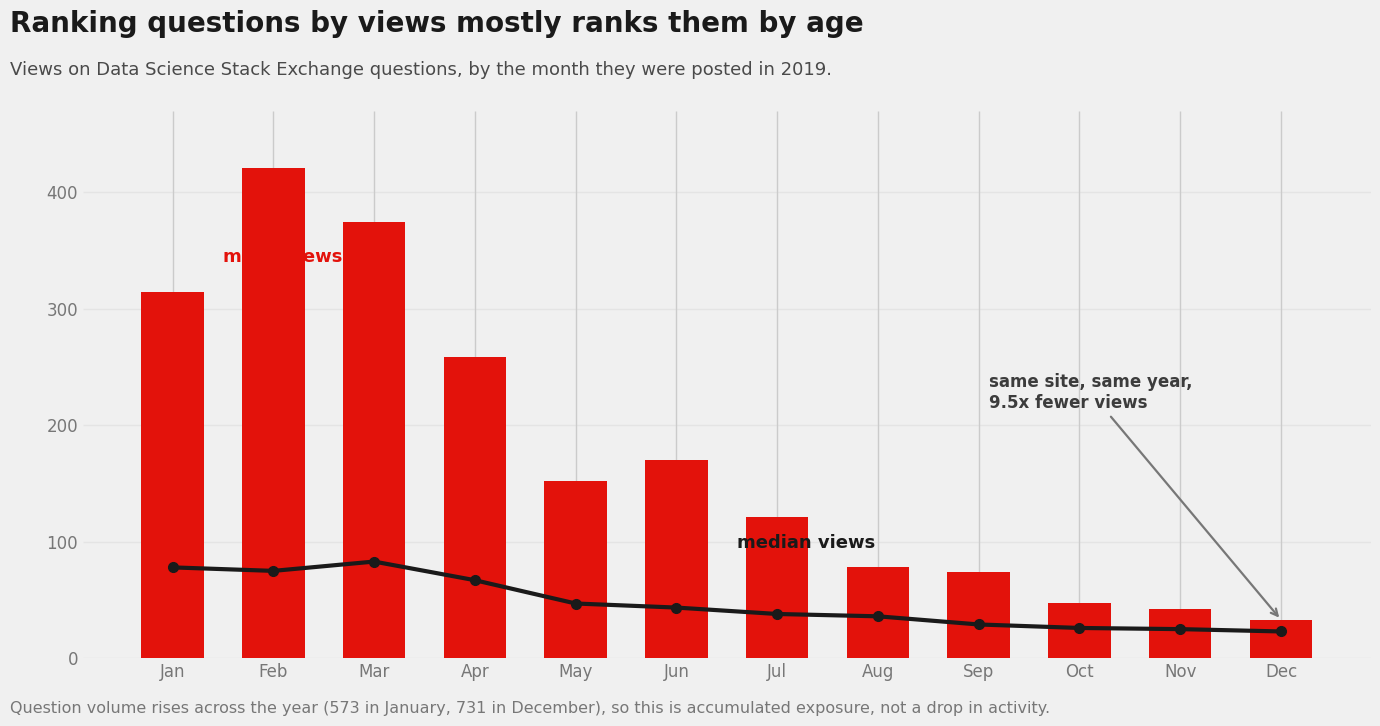

In [7]:
plt.style.use("fivethirtyeight")

C_HOT = "#e3120b"
C_COOL = "#2e86ab"
C_GREY = "#9a9a9a"

def audit(fig, label):
    """Confirm hand-placed text sits inside the canvas instead of trusting the eye."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    bad = []
    for t in fig.texts:
        bb = t.get_window_extent(renderer=r).transformed(fig.transFigure.inverted())
        if bb.y1 > 1.0 or bb.y0 < 0.0 or bb.x1 > 1.0 or bb.x0 < 0.0:
            bad.append((t.get_text()[:40], round(bb.y0, 3), round(bb.y1, 3)))
    print("%s: %d figure texts, %d out of bounds" % (label, len(fig.texts), len(bad)))
    for b in bad:
        print("   OUT OF BOUNDS:", b)
    return len(bad) == 0

# Chart 1: the age bias
fig, ax = plt.subplots(figsize=(14, 7.5))
ax.bar(by_month.index, by_month["mean_views"], color=C_HOT, width=0.62, zorder=3, label="mean")
ax.plot(by_month.index, by_month["median_views"], color="#1a1a1a", linewidth=3,
        marker="o", markersize=7, zorder=4, label="median")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], fontsize=12)
ax.set_ylim(0, 470)
ax.tick_params(labelsize=12, colors="#777777")
ax.grid(alpha=0.3, axis="y")
for s in ax.spines.values():
    s.set_visible(False)
ax.text(1.5, 340, "mean views", color=C_HOT, fontsize=13, weight="bold")
ax.text(6.6, 95, "median views", color="#1a1a1a", fontsize=13, weight="bold")
ax.annotate("same site, same year,\n9.5x fewer views", xy=(12, 33), xytext=(9.1, 215),
            fontsize=12, color="#3c3c3c", weight="bold",
            arrowprops=dict(arrowstyle="->", color="#777777", linewidth=1.6))

fig.subplots_adjust(left=0.065, right=0.985, top=0.825, bottom=0.095)
fig.text(0.013, 0.930, "Ranking questions by views mostly ranks them by age",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.873, "Views on Data Science Stack Exchange questions, by the month they were posted in 2019.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.022, "Question volume rises across the year (573 in January, 731 in December), so this is accumulated exposure, not a drop in activity.",
         fontsize=11.5, color="#777777")
ok1 = audit(fig, "Chart 1")
plt.show()

Chart 2: 3 figure texts, 0 out of bounds


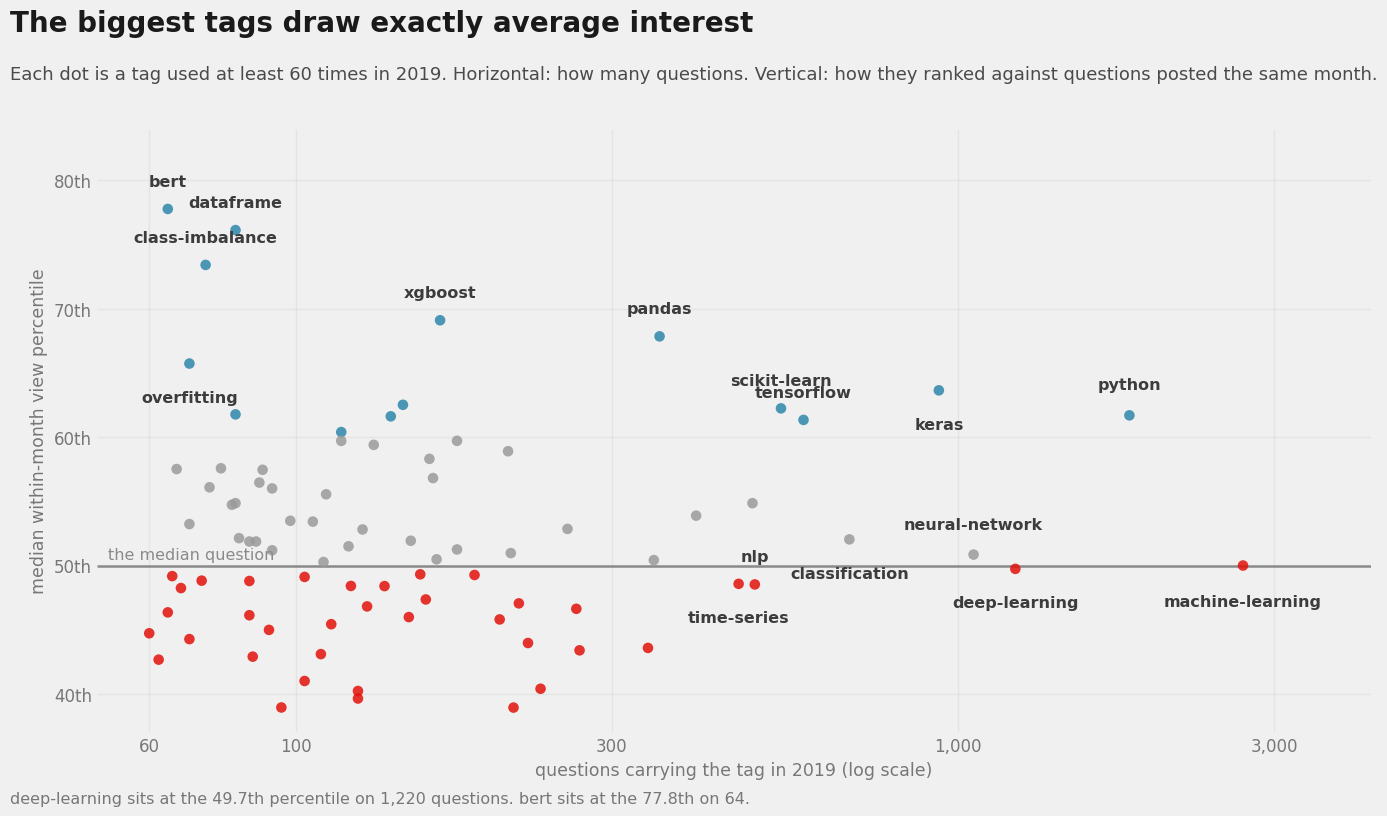

In [8]:
# Chart 2: volume against engagement, which separates "big" from "interesting"
LABEL = ["deep-learning", "machine-learning", "neural-network", "python", "keras",
         "bert", "dataframe", "class-imbalance", "xgboost", "pandas", "overfitting",
         "nlp", "time-series", "scikit-learn", "classification", "tensorflow"]

fig, ax = plt.subplots(figsize=(14, 8.5))
ax.axhline(0.5, color="#8a8a8a", linewidth=1.8, zorder=2)

for _, r in tags.iterrows():
    above = r["median_pctile"] >= 0.60
    colour = C_COOL if above else (C_HOT if r["median_pctile"] <= 0.50 else C_GREY)
    ax.scatter(r["questions"], r["median_pctile"], s=58, color=colour,
               alpha=0.85, zorder=3, edgecolors="none")

offsets = {"deep-learning": (0, -0.030), "machine-learning": (0, -0.032),
           "neural-network": (0, 0.020), "python": (0, 0.020), "keras": (0, -0.030),
           "bert": (0, 0.018), "dataframe": (0, 0.018), "class-imbalance": (0, 0.018),
           "xgboost": (0, 0.018), "pandas": (0, 0.018), "overfitting": (0, -0.030),
           "nlp": (0, 0.018), "time-series": (0, -0.030), "scikit-learn": (0, 0.018),
           "classification": (0, -0.030), "tensorflow": (0, 0.018)}
for t in LABEL:
    r = tags[tags["tag"] == t].iloc[0]
    dx, dy = offsets.get(t, (0, 0.018))
    ax.text(r["questions"] * (1 + dx), r["median_pctile"] + dy, t,
            fontsize=11.5, ha="center", color="#3c3c3c", weight="bold")

ax.set_xscale("log")
ax.set_xlim(50, 4200)
ax.set_ylim(0.37, 0.84)
ax.set_xticks([60, 100, 300, 1000, 3000])
ax.set_xticklabels(["60", "100", "300", "1,000", "3,000"], fontsize=12)
ax.set_yticks([0.4, 0.5, 0.6, 0.7, 0.8])
ax.set_yticklabels(["40th", "50th", "60th", "70th", "80th"], fontsize=12)
ax.set_xlabel("questions carrying the tag in 2019 (log scale)", fontsize=12.5, color="#777777")
ax.set_ylabel("median within-month view percentile", fontsize=12.5, color="#777777")
ax.tick_params(colors="#777777")
ax.grid(alpha=0.3)
for s in ax.spines.values():
    s.set_visible(False)
ax.text(52, 0.505, "the median question", fontsize=11.5, color="#8a8a8a")

fig.subplots_adjust(left=0.075, right=0.985, top=0.815, bottom=0.105)
fig.text(0.013, 0.930, "The biggest tags draw exactly average interest",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.873,
         "Each dot is a tag used at least 60 times in 2019. Horizontal: how many questions. Vertical: how they ranked against questions posted the same month.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.022,
         "deep-learning sits at the 49.7th percentile on 1,220 questions. bert sits at the 77.8th on 64.",
         fontsize=11.5, color="#777777")
ok2 = audit(fig, "Chart 2")
plt.show()

Chart 3: 3 figure texts, 0 out of bounds

all charts within bounds: True


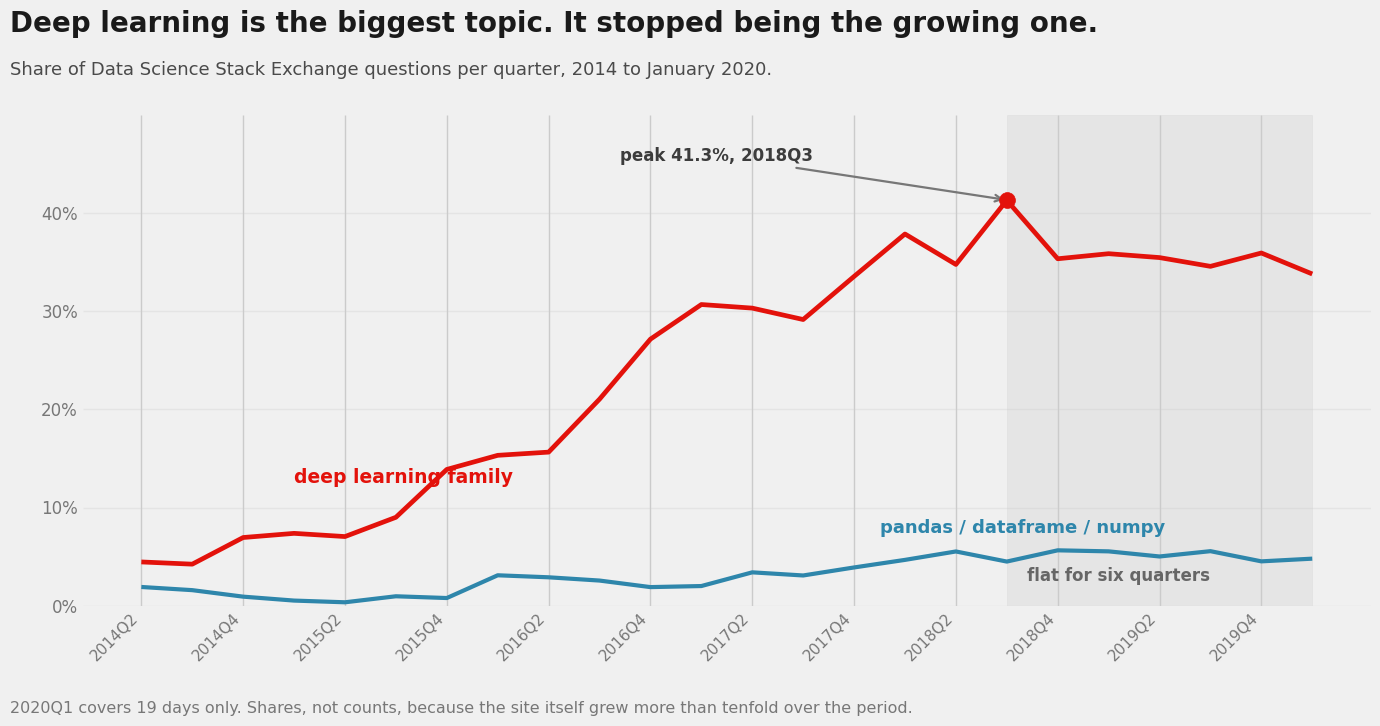

In [9]:
# Chart 3: the plateau
q_index = range(len(trend))
labels = [str(p) for p in trend.index]

fig, ax = plt.subplots(figsize=(14, 7.5))
ax.plot(q_index, trend["dl_pct"], color=C_HOT, linewidth=3.4, zorder=3)
ax.plot(q_index, trend["pandas_pct"], color=C_COOL, linewidth=3.0, zorder=3)

peak_i = list(trend.index).index(trend["dl_pct"].idxmax())
ax.scatter([peak_i], [trend["dl_pct"].max()], s=130, color=C_HOT, zorder=5)
ax.axvspan(peak_i, len(trend) - 1, color="#cccccc", alpha=0.30, zorder=1)

ax.set_xticks(list(q_index)[::2])
ax.set_xticklabels(labels[::2], fontsize=11, rotation=45, ha="right")
ax.set_ylim(0, 50)
ax.set_yticks([0, 10, 20, 30, 40])
ax.set_yticklabels(["0%", "10%", "20%", "30%", "40%"], fontsize=12)
ax.tick_params(colors="#777777")
ax.grid(alpha=0.3, axis="y")
for s in ax.spines.values():
    s.set_visible(False)

ax.text(3.0, 12.5, "deep learning family", color=C_HOT, fontsize=13.5, weight="bold")
ax.text(14.5, 7.4, "pandas / dataframe / numpy", color=C_COOL, fontsize=13, weight="bold")
ax.annotate("peak 41.3%, 2018Q3", xy=(peak_i, 41.3), xytext=(9.4, 45.3),
            fontsize=12, color="#3c3c3c", weight="bold",
            arrowprops=dict(arrowstyle="->", color="#777777", linewidth=1.6))
ax.text(peak_i + 0.4, 2.5, "flat for six quarters", fontsize=12, color="#666666", weight="bold")

fig.subplots_adjust(left=0.065, right=0.985, top=0.820, bottom=0.165)
fig.text(0.013, 0.930, "Deep learning is the biggest topic. It stopped being the growing one.",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.873, "Share of Data Science Stack Exchange questions per quarter, 2014 to January 2020.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.022, "2020Q1 covers 19 days only. Shares, not counts, because the site itself grew more than tenfold over the period.",
         fontsize=11.5, color="#777777")
ok3 = audit(fig, "Chart 3")
print()
print("all charts within bounds:", bool(ok1 and ok2 and ok3))
plt.show()

## 7. Conclusions

### The recommendation

**Do not commission a deep learning series on the strength of its view counts.** Write deep learning content because a third of the audience is already there, and write the specific practical pieces because they are what people actually read.

Concretely, the tags that over-perform their contemporaries are **bert, dataframe manipulation, class imbalance, xgboost, pandas, overfitting, decision trees** and **cross-validation**. These are narrow, answerable, hands-on topics. The tags that under-perform are the broad ones.

### Three reasons the standard answer does not support its own conclusion

**1. Views measure age as much as interest.** A question posted in January 2019 averages **9.5 times** the views of one posted in December (314.5 against 33.1), on a site where question volume was *rising* across the year. The correlation between day-of-year and log views is -0.40. Any tag whose use grew during 2019 is penalised by this metric and any tag that faded is flattered.

**2. Total views rewards volume, not interest.** Total views is volume multiplied by interest per question. Ranked against the questions posted in the same month, the headline tags sit at dead centre:

| Tag | Questions | Median view percentile | Engagement rank |
|---|---|---|---|
| deep-learning | 1,220 | **0.497** | 51 of 89 |
| machine-learning | 2,693 | **0.500** | 50 of 89 |
| neural-network | 1,055 | 0.509 | - |

A deep learning question is, to three decimals, the median question on the site. It accumulates 233,628 views because 1,220 questions carry the tag, not because any of them drew a crowd.

For contrast, **bert** sits at the 0.778 percentile on 64 questions and **dataframe** at 0.761 on 81. Neither appears anywhere near the top of the standard ranking.

**3. Tags are not topics.** `deep-learning`, `neural-network`, `keras`, `tensorflow`, `cnn`, `lstm` and `pytorch` describe one area, and 58.4% of deep-learning questions carry at least one of the others. Counting tags separately splits the topic; counting the union shows it touches **35.4% of all 2019 questions**, far more than the 13.8% the single tag suggests.

### The growth story ended before the data did

| Period | Deep learning share |
|---|---|
| 2014Q2 | 4.5% |
| 2016Q4 | 27.1% |
| 2017Q4 | 33.5% |
| **2018Q3** | **41.3% (peak)** |
| 2019Q1 to 2019Q4 | 35.8%, 35.4%, 34.5%, 35.9% |

Deep learning grew ninefold as a share of the site between 2014 and 2018, then went flat for six straight quarters. "Most popular right now" is true; "the topic to bet on" does not follow from it, and a view-count ranking cannot tell the two apart.

Meanwhile `bert` appears from nothing in 2019 (6, 21, 8, 29 questions by quarter) and is the highest-engagement tag in the corrected ranking. Small, new, and over-performing is what a growth opportunity looks like in this data.

### What I would not claim

- **Views are a weak proxy for the thing we care about.** Readers of a tutorial are not askers of a question, and a question drawing views may mean the documentation is bad rather than the topic is interesting.
- **The percentile correction handles age, not everything else.** Google indexing, inbound links from other sites, and whether a question was ever answered all drive views, and only the last of those is in this file.
- **The 60-question threshold is a judgement call.** It leaves 89 tags. Lowering it admits noisier tags with wilder percentiles; raising it would drop `bert` (64) entirely, which would have hidden the most interesting finding.
- **bert rests on 64 questions.** Its 0.778 percentile is a real signal but a thin one, and I would want 2020 data before committing a content budget to it.
- **The deep learning family is my grouping.** Nine tags chosen by hand. A different grouping shifts the 35.4% figure, though not enough to change the plateau.
- **This is one Stack Exchange site.** DSSE skews toward practitioners debugging code. It is not a survey of the field.

---

*Dataset: Data Science Stack Exchange public question data, retrieved via the Stack Exchange Data Explorer.*